# 05 · Recuit simulé (SA)

## Le principe, appliqué au placement de qubits

Le recuit simulé fait évoluer **une seule solution**, pas à pas :

1. on part d'un placement ;
2. on propose un **voisin** : le même placement après l'échange de deux qubits (deux qubits logiques échangent leurs qubits physiques, ou un qubit logique part sur un qubit physique libre) ;
3. on évalue ce voisin avec la vraie fitness ;
4. **règle d'acceptation (Metropolis)** : un voisin meilleur ou égal est toujours accepté ; un voisin **pire** de Δ est accepté avec la probabilité **exp(−Δ / T)** ;
5. la **température** T baisse au fil des évaluations : au début, on accepte souvent des dégradations (exploration, pour sortir des minimums locaux) ; à la fin, presque plus (on affine).

**Choix d'adaptation à ce projet :**
- **Température relative** : T = t × coût de départ. Avec `t_start = 0.05`, une dégradation de 5 % du coût de départ est acceptée avec une probabilité exp(−1) ≈ 37 % au début. Les mêmes réglages conviennent ainsi à une instance qui coûte 25 et à une qui coûte 330.
- **Refroidissement géométrique calé sur le budget** : T passe de `t_start` à `t_end` (en proportion du coût de départ) exactement sur le budget disponible.
- **Point de départ** : par défaut un placement optimisé gratuitement pour le coût de distance (`start = "surrogate"`), ou l'identité, ou un placement aléatoire.
- **Présélection des voisins** (`candidates > 1`) : on génère plusieurs voisins et on n'évalue que le meilleur selon le coût de distance, comme le filtrage des fourmis.

Le recuit simulé travaille directement sur la vraie fitness autour d'une solution : il complète les fourmis, qui s'appuient beaucoup sur le coût de distance.

L'algorithme est dans `optimizer/algorithms/simulated_annealing.py`. La comparaison de toutes les métaheuristiques entre elles est dans le notebook `99_comparison`.

In [1]:
import math
import os
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats  # test statistique de Mann-Whitney

from goc import hardware
from goc.paths import RESULTS_ROOT, SOLUTIONS_ROOT
# Socle d'optimisation : instances, vraie fitness, coût de distance, lancement et sauvegarde des exécutions.
from optimizer import Problem, available_instances, distance_cost, history_frame, load_instance, load_results, results_frame, run_grid, save_results, write_solution_if_better
# Algorithmes : recuit simulé, fourmis et références.
from optimizer.algorithms import ant_colony, identity, random_search, simulated_annealing, surrogate_filtered

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

- `BUDGET`, `SEEDS` : identiques au notebook 04, pour pouvoir réutiliser ses exécutions des références et des fourmis.
- `BASE_SA` : réglage de référence du recuit simulé ; `ACO_BASE` : celui des fourmis (notebook 04).
- Les exécutions sont enregistrées dans `results/simulated_annealing/` ; mets `RECOMPUTE = True` pour les refaire.

In [3]:
# Instance utilisée pour l'exécution détaillée (section 1).
INSTANCE_ID = 9
# Graine de l'exécution détaillée.
SEED = 0
# Nombre de vraies évaluations par exécution : le même que dans le notebook 04, pour comparer directement.
BUDGET = 200
# Graines de la comparaison finale (les mêmes que dans le notebook 04).
SEEDS = [0, 1, 2, 3, 4]
# Instances de la comparaison finale.
COMPARISON_INSTANCES = available_instances()
# Instances et graines des études de paramètres (3 : coût de distance peu fiable, 9 : très fiable).
STUDY_INSTANCES = [3, 9]
STUDY_SEEDS = [0, 1, 2]
# Nombre de réévaluations des meilleures solutions (section 4).
REEVALUATIONS = 10
# Nombre de processus en parallèle.
WORKERS = max(1, (os.cpu_count() or 2) - 4)
# False : relire les exécutions enregistrées ; True : tout recalculer (≈ 15 minutes).
RECOMPUTE = False
# Dossier où les exécutions de ce notebook sont enregistrées.
CACHE_DIR = RESULTS_ROOT / "simulated_annealing"
# Exécutions des références et des fourmis du notebook 04 (relues, pas recalculées).
BASELINES_PATH = RESULTS_ROOT / "ant_colony" / "comparison.jsonl"
# Nom du groupe pour les fichiers solutions, et dossier où ils sont écrits.
GROUP = "Groupe0"
SOLUTIONS_DIR = SOLUTIONS_ROOT

# Réglage de référence du recuit simulé (voir optimizer/algorithms/simulated_annealing.py).
BASE_SA = {
    "t_start": 0.05,  # température de départ : 5 % du coût de départ
    "t_end": 0.002,  # température finale : 0,2 % du coût de départ
    "start": "surrogate",  # départ : placement optimisé pour le coût de distance
    "start_descent_steps": 2000,  # échanges de la descente gratuite de départ
    "candidates": 1,  # un seul voisin par pas (recuit classique)
}
# Réglage de référence des fourmis (le même que dans le notebook 04), sans copies de la matrice des phéromones.
ACO_BASE = {"ants": 30, "evaluated": 5, "alpha": 1.0, "beta": 2.0, "rho": 0.2, "tau_min_ratio": 0.05, "elite_weight": 1.0, "local_search_steps": 0, "snapshot_every": 10**6}

In [4]:
def cached_grid(name, algorithms, instance_ids, seeds, budget):
    """Lance run_grid, ou relit le résultat déjà enregistré dans CACHE_DIR/<name>.jsonl."""
    path = CACHE_DIR / f"{name}.jsonl"
    if path.exists() and not RECOMPUTE:
        results = load_results(path)
        print(f"Loaded {len(results)} runs from {path}")
        return results
    results = run_grid(algorithms, instance_ids, seeds, budget, workers=WORKERS)
    save_results(results, path)
    return results


def steps_frame(result):
    """Tableau des pas du recuit simulé enregistrés dans la trace (une ligne par voisin évalué)."""
    return pd.DataFrame(result.trace["sa_steps"])


def distance_color(distance):
    """Couleur associée à une distance sur la puce (3 et plus partagent la même couleur rouge)."""
    return DISTANCE_COLORS[min(int(distance), 3)]


def display_table(frame, value="best_cost"):
    """Tableau lisible : pour chaque algorithme et instance, « moyenne ± écart-type (meilleur) »."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")

## Le cycle de l'algorithme et sa règle d'acceptation

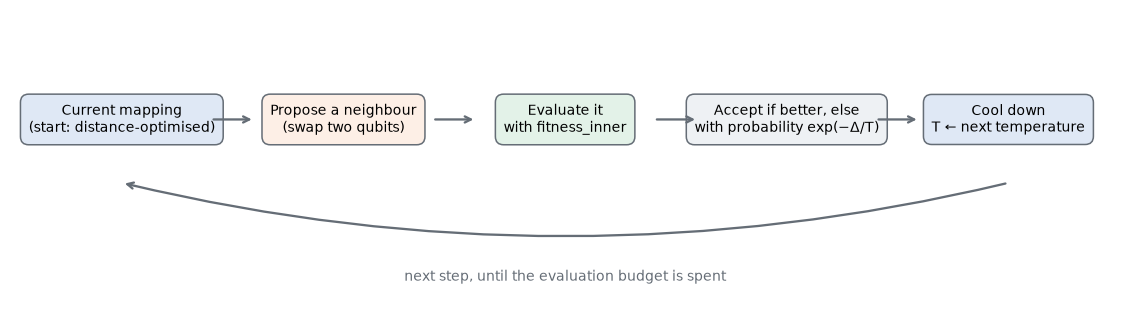

In [5]:
def plot_sa_cycle():
    """Schéma d'un pas du recuit simulé."""
    fig, ax = plt.subplots(figsize=(13, 3.4))
    boxes = [
        ("Current mapping\n(start: distance-optimised)", PHYSICAL_SOFT),
        ("Propose a neighbour\n(swap two qubits)", LOGICAL_SOFT),
        ("Evaluate it\nwith fitness_inner", "#e3f2e8"),
        ("Accept if better, else\nwith probability exp(−Δ/T)", "#eef1f4"),
        ("Cool down\nT ← next temperature", PHYSICAL_SOFT),
    ]
    xs = np.linspace(0.1, 0.9, len(boxes))
    for x, (text, color) in zip(xs, boxes):
        ax.text(x, 0.62, text, ha="center", va="center", fontsize=9, transform=ax.transAxes, bbox={"boxstyle": "round,pad=0.6", "fc": color, "ec": MUTED})
    for a, b in zip(xs[:-1], xs[1:]):
        ax.annotate("", xy=(b - 0.08, 0.62), xytext=(a + 0.08, 0.62), xycoords="axes fraction", arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 1.5})
    ax.annotate("", xy=(xs[0], 0.4), xytext=(xs[-1], 0.4), xycoords="axes fraction", arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 1.5, "connectionstyle": "arc3,rad=-0.12"})
    ax.text(0.5, 0.06, "next step, until the evaluation budget is spent", ha="center", transform=ax.transAxes, color=MUTED, fontsize=9)
    ax.set_axis_off()
    return fig


plot_sa_cycle();

**À gauche** : probabilité d'accepter une dégradation Δ (en % du coût de départ) selon la température relative. **À droite** : la température au fil du budget pour plusieurs `t_start` (échelle logarithmique) : elle descend jusqu'à `t_end` exactement à la fin du budget.

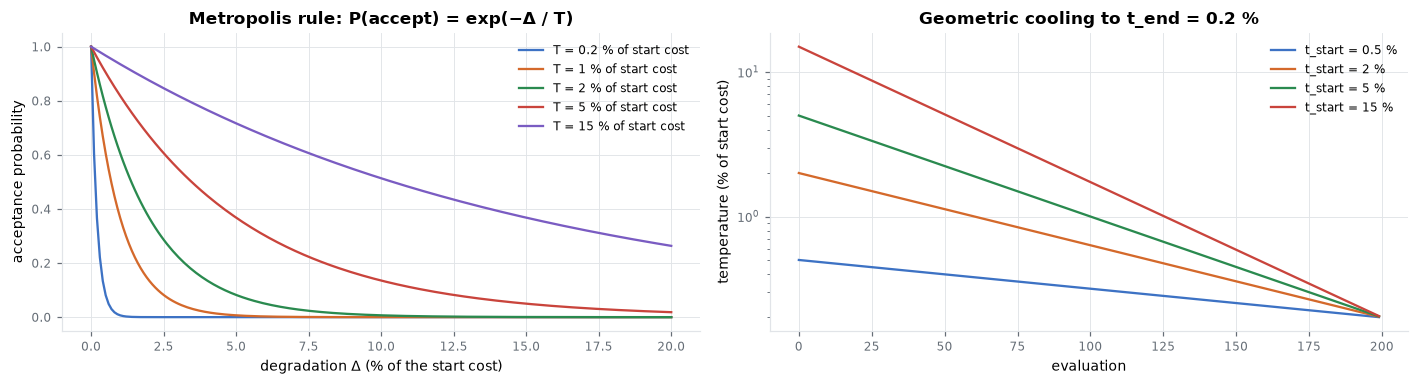

In [6]:
def plot_acceptance_theory(t_starts=(0.005, 0.02, 0.05, 0.15), t_end=0.002, budget=200):
    """Probabilité d'acceptation exp(−Δ/T) et programme de refroidissement géométrique."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.6))
    # Dégradation relative au coût de départ, de 0 à 20 %.
    deltas = np.linspace(0, 0.2, 200)
    for color, t in zip(PALETTE, (0.002, 0.01, 0.02, 0.05, 0.15)):
        left.plot(100 * deltas, np.exp(-deltas / t), color=color, label=f"T = {100 * t:g} % of start cost")
    left.set_xlabel("degradation Δ (% of the start cost)")
    left.set_ylabel("acceptance probability")
    left.set_title("Metropolis rule: P(accept) = exp(−Δ / T)")
    left.legend()
    # Avancement de 0 à 1 sur le budget, et température correspondante.
    steps = np.arange(budget)
    for color, t_start in zip(PALETTE, t_starts):
        right.plot(steps, 100 * simulated_annealing.temperature(steps / budget, t_start, t_end), color=color, label=f"t_start = {100 * t_start:g} %")
    right.set_yscale("log")
    right.set_xlabel("evaluation")
    right.set_ylabel("temperature (% of start cost)")
    right.set_title(f"Geometric cooling to t_end = {100 * t_end:g} %")
    right.legend()
    fig.tight_layout()
    return fig


plot_acceptance_theory();

## 1. Une exécution détaillée

Le recuit simulé de référence (`BASE_SA`) tourne sur l'instance choisie avec le budget complet. Chaque pas est enregistré dans `result.trace["sa_steps"]` : voisin proposé, son coût, acceptation, température, meilleur coût.

In [7]:
instance = load_instance(INSTANCE_ID)
coordinates = np.array(hardware.coordinates(instance.m, instance.edges), dtype=float)
# Une seule exécution (relue depuis results/ si elle existe déjà).
single = cached_grid(f"single_run_instance_{INSTANCE_ID}", {"simulated_annealing": (simulated_annealing.run, BASE_SA)}, [INSTANCE_ID], [SEED], BUDGET)[0]
steps = steps_frame(single)
print(f"start cost {single.trace['sa_start_cost']} -> best {single.best_cost} after {single.evaluations} evaluations ({single.seconds:.1f} s)")
# Résumé de l'exécution : nombre de voisins acceptés, améliorations, dégradations acceptées.
run_summary = pd.Series({
    "start cost": single.trace["sa_start_cost"],
    "start distance cost": single.trace["sa_start_surrogate"],
    "best cost": single.best_cost,
    "neighbours evaluated": len(steps),
    "accepted": int(steps["accepted"].sum()),
    "improving or equal moves": int((steps["delta"] <= 0).sum()),
    "worsening moves accepted": int(((steps["delta"] > 0) & steps["accepted"]).sum()),
    "worsening moves rejected": int(((steps["delta"] > 0) & ~steps["accepted"]).sum()),
}, name="value").astype(str).to_frame()
run_summary

Loaded 1 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\simulated_annealing\single_run_instance_9.jsonl
start cost 81 -> best 59 after 200 evaluations (10.8 s)


,value
start cost,81
start distance cost,14
best cost,59
neighbours evaluated,199
accepted,16
improving or equal moves,14
worsening moves accepted,2
worsening moves rejected,183


**Trajectoire.** Chaque point est un voisin évalué : vert s'il est accepté, gris s'il est refusé. La ligne bleue est le coût du placement courant, la verte le meilleur coût trouvé ; la température (axe de droite, en pointillés) descend au fil du budget. Au début, la ligne bleue remonte parfois (dégradations acceptées) ; à la fin, elle ne fait plus que descendre ou rester stable.

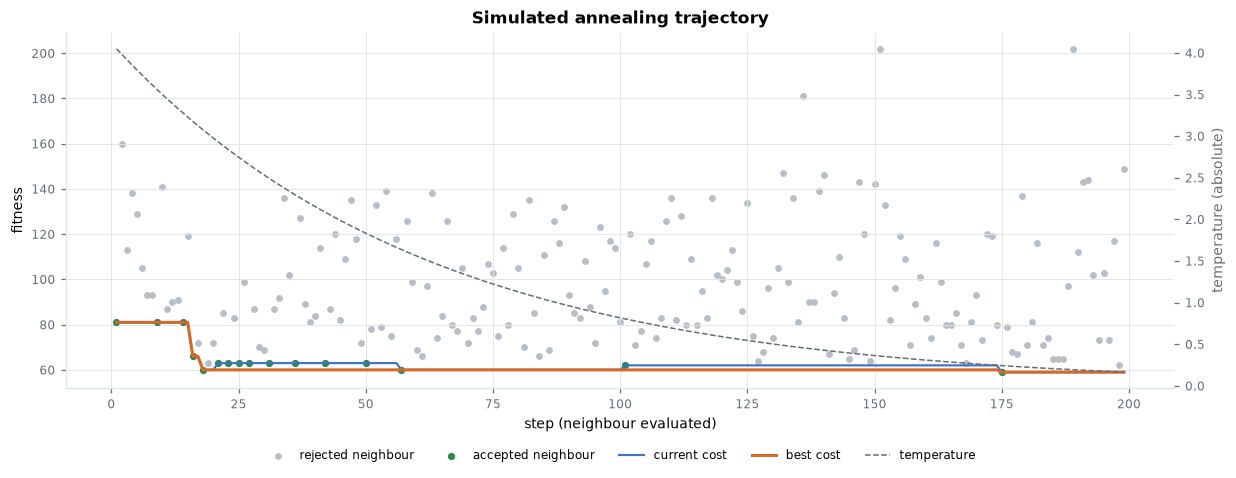

In [8]:
def plot_trajectory(result):
    """Coûts des voisins (acceptés/refusés), coût courant, meilleur coût et température au fil des pas."""
    frame = steps_frame(result)
    fig, ax = plt.subplots(figsize=(13, 4.2))
    accepted = frame[frame["accepted"]]
    rejected = frame[~frame["accepted"]]
    ax.scatter(rejected["step"], rejected["candidate_cost"], s=12, color="#b8bec6", label="rejected neighbour", zorder=1)
    ax.scatter(accepted["step"], accepted["candidate_cost"], s=14, color=DISTANCE_COLORS[1], label="accepted neighbour", zorder=2)
    ax.plot(frame["step"], frame["current_cost"], color=PHYSICAL, linewidth=1.4, label="current cost", zorder=3)
    ax.plot(frame["step"], frame["best"], color=LOGICAL, linewidth=2, label="best cost", zorder=4)
    ax.set_xlabel("step (neighbour evaluated)")
    ax.set_ylabel("fitness")
    ax.set_title("Simulated annealing trajectory")
    # Second axe vertical pour la température.
    twin = ax.twinx()
    twin.plot(frame["step"], frame["temperature"], color=MUTED, linestyle="--", linewidth=1, label="temperature")
    twin.set_ylabel("temperature (absolute)", color=MUTED)
    twin.grid(False)
    # Légende commune aux deux axes.
    handles = ax.get_legend_handles_labels()[0] + twin.get_legend_handles_labels()[0]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=5)
    return fig


plot_trajectory(single);

**Acceptation.** À gauche : taux d'acceptation des dégradations sur une fenêtre glissante de 20 pas ; il doit baisser en même temps que la température. À droite : la répartition des écarts Δ entre voisin et placement courant, séparée entre voisins acceptés et refusés.

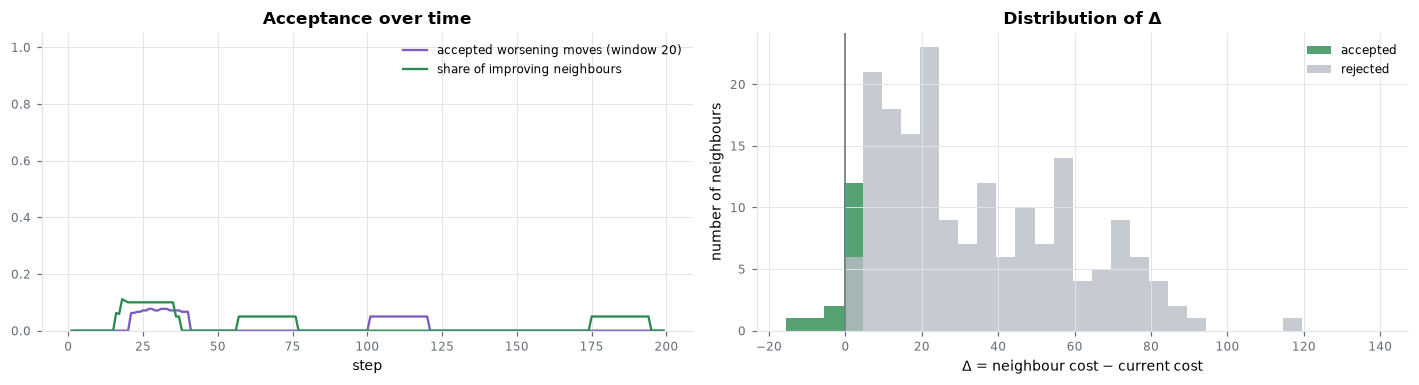

In [9]:
def plot_acceptance(result, window=20):
    """Taux d'acceptation des dégradations (fenêtre glissante) et histogramme des écarts Δ."""
    frame = steps_frame(result)
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 3.6))
    worsening = frame["delta"] > 0
    # Parmi les dégradations des `window` derniers pas, part de celles acceptées.
    rate = (frame["accepted"] & worsening).rolling(window, min_periods=1).sum() / worsening.rolling(window, min_periods=1).sum().replace(0, np.nan)
    left.plot(frame["step"], rate, color=PALETTE[4], label=f"accepted worsening moves (window {window})")
    improving = (frame["delta"] < 0).rolling(window, min_periods=1).mean()
    left.plot(frame["step"], improving, color=DISTANCE_COLORS[1], label="share of improving neighbours")
    left.set_ylim(0, 1.05)
    left.set_xlabel("step")
    left.set_title("Acceptance over time")
    left.legend()
    bins = np.arange(frame["delta"].min() - 0.5, frame["delta"].max() + 1.5, max(1, (frame["delta"].max() - frame["delta"].min()) // 30 or 1))
    right.hist(frame.loc[frame["accepted"], "delta"], bins=bins, color=DISTANCE_COLORS[1], alpha=0.8, label="accepted")
    right.hist(frame.loc[~frame["accepted"], "delta"], bins=bins, color="#b8bec6", alpha=0.8, label="rejected")
    right.axvline(0, color=MUTED, linewidth=1)
    right.set_xlabel("Δ = neighbour cost − current cost")
    right.set_ylabel("number of neighbours")
    right.set_title("Distribution of Δ")
    right.legend()
    fig.tight_layout()
    return fig


plot_acceptance(single);

**Coût de distance des voisins.** Chaque point est un voisin évalué : son coût de distance (gratuit) en abscisse, sa vraie fitness en ordonnée, la couleur indique le moment de l'exécution. Sur une instance où les deux sont bien corrélés (notebook 02), le nuage monte de gauche à droite : présélectionner les voisins par coût de distance (`candidates > 1`) devrait alors aider.

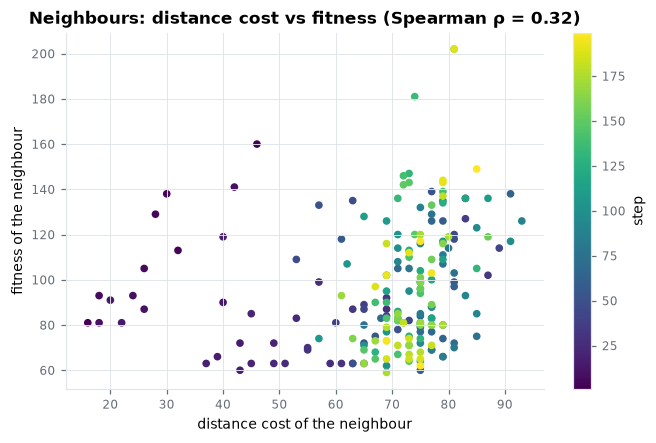

In [10]:
def plot_surrogate_vs_fitness(result):
    """Nuage coût de distance / vraie fitness des voisins évalués, coloré selon le pas."""
    frame = steps_frame(result)
    fig, ax = plt.subplots(figsize=(7, 4.2))
    points = ax.scatter(frame["candidate_surrogate"], frame["candidate_cost"], c=frame["step"], cmap="viridis", s=16)
    fig.colorbar(points, ax=ax, label="step")
    rho = stats.spearmanr(frame["candidate_surrogate"], frame["candidate_cost"]).statistic
    ax.set_xlabel("distance cost of the neighbour")
    ax.set_ylabel("fitness of the neighbour")
    ax.set_title(f"Neighbours: distance cost vs fitness (Spearman ρ = {rho:.2f})")
    return fig


plot_surrogate_vs_fitness(single);

### Point de départ et meilleur placement

Les deux placements sur la puce : le point de départ (optimisé gratuitement pour le coût de distance) et le meilleur placement trouvé. Ils sont ensuite réévalués `REEVALUATIONS` fois avec l'identité comme référence.

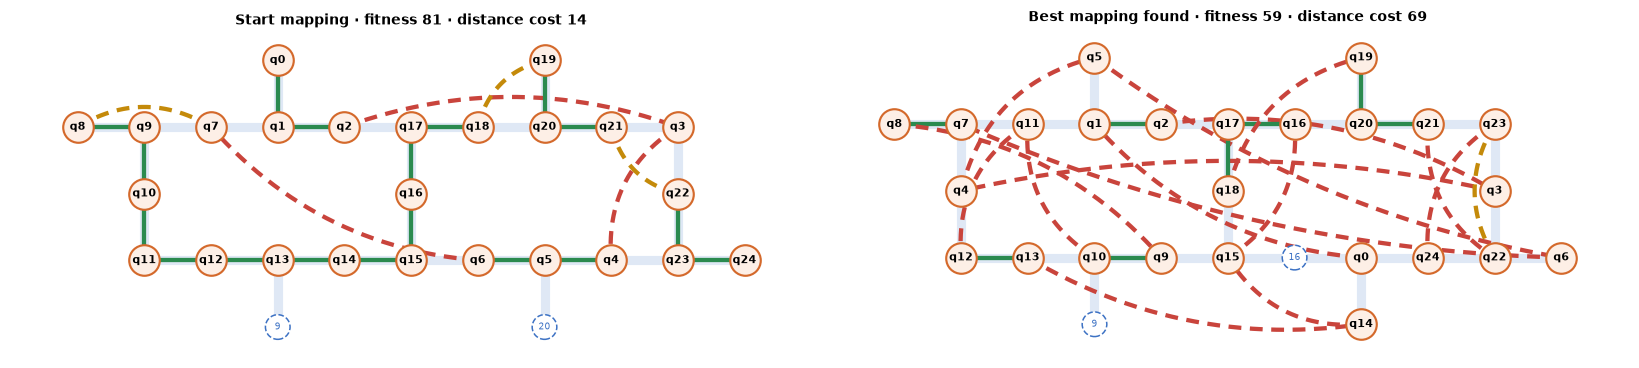

In [11]:
def curve_points(start, end, bend):
    """Points d'une courbe (Bézier quadratique) entre deux positions, décalée de `bend` sur le côté."""
    start, end = np.asarray(start), np.asarray(end)
    direction = end - start
    normal = np.array([-direction[1], direction[0]]) / (np.linalg.norm(direction) or 1)
    control = (start + end) / 2 + normal * bend
    t = np.linspace(0, 1, 30)[:, None]
    return (1 - t) ** 2 * start + 2 * (1 - t) * t * control + t ** 2 * end


def draw_chip(ax, instance, coordinates, mapping, title=""):
    """Dessine la puce avec un placement et les interactions du circuit colorées selon la distance."""
    for a, b in instance.edges:
        ax.plot(*coordinates[[a, b]].T, color=PHYSICAL_SOFT, linewidth=6, solid_capstyle="round", zorder=1)
    max_weight = max(int(instance.weights.max()), 1)
    for index, ((a, b), weight) in enumerate(zip(instance.pairs, instance.weights)):
        pa, pb = mapping[a], mapping[b]
        distance = instance.distances[pa, pb]
        width = 0.8 + 2 * math.sqrt(weight / max_weight)
        if distance == 1:
            ax.plot(*coordinates[[pa, pb]].T, color=distance_color(1), linewidth=width, zorder=2)
        else:
            bend = (0.3 if index % 2 else -0.3) * min(np.linalg.norm(coordinates[pb] - coordinates[pa]), 3)
            points = curve_points(coordinates[pa], coordinates[pb], bend)
            ax.plot(points[:, 0], points[:, 1], color=distance_color(distance), linewidth=width, linestyle=(0, (3, 2)), zorder=2)
    owner = {int(p): q for q, p in enumerate(mapping)}
    for p, (x, y) in enumerate(coordinates):
        if p in owner:
            ax.scatter(x, y, s=400, color=LOGICAL_SOFT, edgecolors=LOGICAL, linewidths=1.4, zorder=3)
            ax.text(x, y, f"q{owner[p]}", ha="center", va="center", fontsize=7, fontweight="bold", zorder=4)
        else:
            ax.scatter(x, y, s=260, color="white", edgecolors=PHYSICAL, linewidths=1, linestyle="--", zorder=3)
            ax.text(x, y, str(p), ha="center", va="center", fontsize=6, color=PHYSICAL, zorder=4)
    ax.set_title(title, fontsize=9)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.margins(0.1)
    ax.set_axis_off()


start_mapping = single.trace["sa_start_mapping"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
draw_chip(axes[0], instance, coordinates, start_mapping, title=f"Start mapping · fitness {single.trace['sa_start_cost']} · distance cost {distance_cost(instance, start_mapping)}")
draw_chip(axes[1], instance, coordinates, single.best_mapping, title=f"Best mapping found · fitness {single.best_cost} · distance cost {distance_cost(instance, single.best_mapping)}")
fig.tight_layout()

In [12]:
# Réévaluation des placements pour les comparer hors du bruit d'une seule évaluation.
checker = Problem(instance)
candidates = {"start mapping": start_mapping, "best mapping found": single.best_mapping, "identity": list(range(instance.n))}
rows = []
for label, mapping in candidates.items():
    costs = checker.fitness_samples(mapping, REEVALUATIONS)
    rows.append({"mapping": label, "distance cost": distance_cost(instance, mapping), "min": min(costs), "mean": round(float(np.mean(costs)), 2), "max": max(costs), "std": round(float(np.std(costs)), 2)})
check_table = pd.DataFrame(rows).set_index("mapping")
check_table

,distance cost,min,mean,max,std
mapping,,,,,
start mapping,14,81,81.0,81,0.00
best mapping found,69,59,63.5,71,3.85
identity,50,137,137.0,137,0.00


## 2. Effet des paramètres

Chaque étude fait varier **un seul** paramètre autour de `BASE_SA`, sur les instances **3** (QFT, coût de distance peu fiable) et **9** (GHZ en chaîne, coût de distance très fiable), avec plusieurs graines et le même budget.

En haut : le meilleur coût final (une boîte = les graines). En bas : la convergence moyenne.

In [13]:
def plot_study(results, title):
    """Pour chaque instance : boîtes du meilleur coût final (en haut) et convergence moyenne (en bas), par réglage."""
    frame = results_frame(results)
    order = list(dict.fromkeys(r.algorithm for r in results))
    instance_ids = sorted(frame["instance_id"].unique())
    fig, axes = plt.subplots(2, len(instance_ids), figsize=(5.4 * len(instance_ids), 6.6), squeeze=False)
    for col, instance_id in enumerate(instance_ids):
        subset = frame[frame["instance_id"] == instance_id]
        ax = axes[0, col]
        ax.boxplot([subset.loc[subset["algorithm"] == a, "best_cost"] for a in order], widths=0.5, medianprops={"color": LOGICAL})
        ax.set_xticks(range(1, len(order) + 1), order, fontsize=8)
        ax.set_title(f"Instance {instance_id} · final best fitness")
        history = history_frame([r for r in results if r.instance_id == instance_id])
        ax = axes[1, col]
        for color, algorithm in zip(PALETTE, order):
            curves = history[history["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.5)
        ax.set_title(f"Instance {instance_id} · mean convergence")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
        ax.legend()
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    return fig


def study(name, values, build, algorithm=simulated_annealing.run, base=None):
    """Lance une étude : un réglage par valeur, obtenu en modifiant `base` (BASE_SA par défaut) avec build(valeur)."""
    base = BASE_SA if base is None else base
    algorithms = {label: (algorithm, {**base, **build(value)}) for label, value in values.items()}
    return cached_grid(f"study_{name}", algorithms, STUDY_INSTANCES, STUDY_SEEDS, BUDGET)

### 2.1 Température de départ

`t_start = 0.5 %` : presque aucune dégradation acceptée, c'est quasiment une descente pure. `t_start = 15 %` : on accepte beaucoup de dégradations au début, au risque de gaspiller une partie du budget à errer.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\simulated_annealing\study_temperature.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
t0=0.5%,124.3 ± 8.2 (114),52.0 ± 3.6 (49)
t0=2%,128.0 ± 7.1 (118),58.7 ± 2.4 (57)
t0=5%,126.0 ± 8.5 (114),52.3 ± 10.8 (38)
t0=15%,128.3 ± 7.8 (119),79.0 ± 4.3 (73)


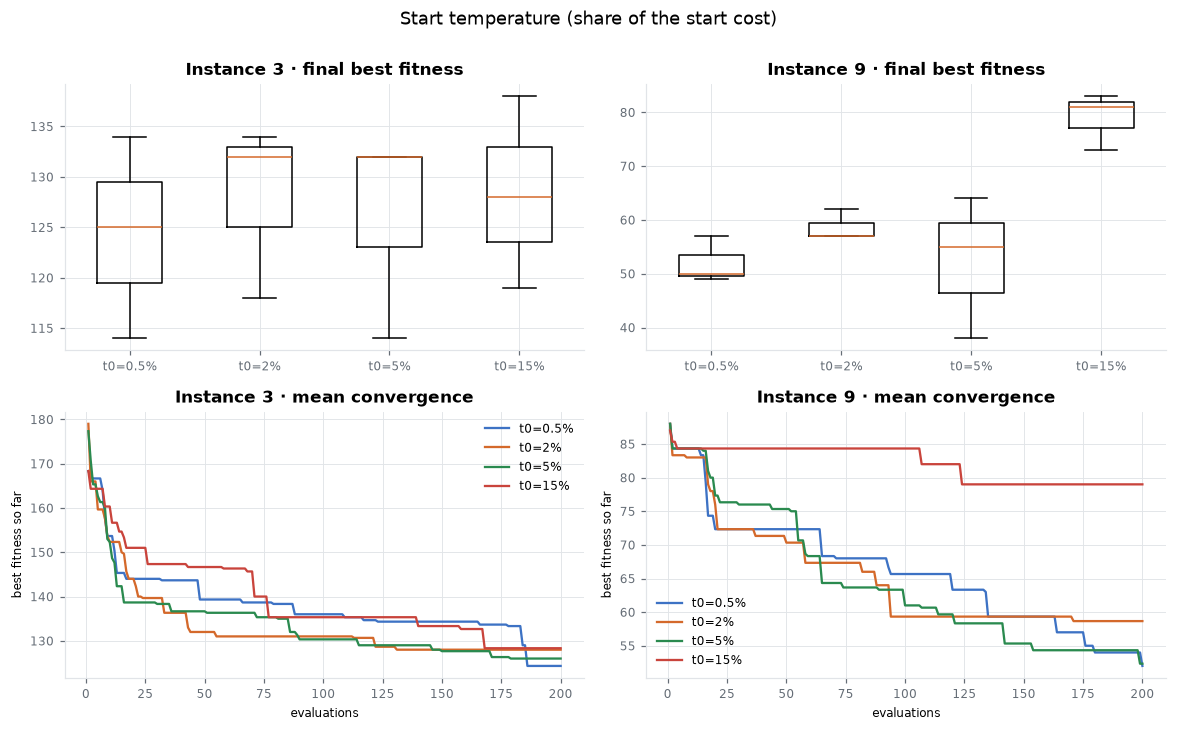

In [14]:
temperature_study = study("temperature", {"t0=0.5%": 0.005, "t0=2%": 0.02, "t0=5%": 0.05, "t0=15%": 0.15}, lambda v: {"t_start": v})
temperature_table = display_table(results_frame(temperature_study))
display(temperature_table)
plot_study(temperature_study, "Start temperature (share of the start cost)");

### 2.2 Point de départ

`random` : placement aléatoire ; `identity` : placement identité ; `surrogate` : placement optimisé gratuitement pour le coût de distance (2000 échanges). Sur les instances où le coût de distance guide mal, un départ « optimisé » peut être un piège.

Loaded 18 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\simulated_annealing\study_start.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
random,128.0 ± 5.7 (120),74.7 ± 13.9 (58)
identity,122.3 ± 11.3 (107),72.7 ± 7.8 (64)
surrogate,133.0 ± 9.1 (121),60.7 ± 9.7 (47)


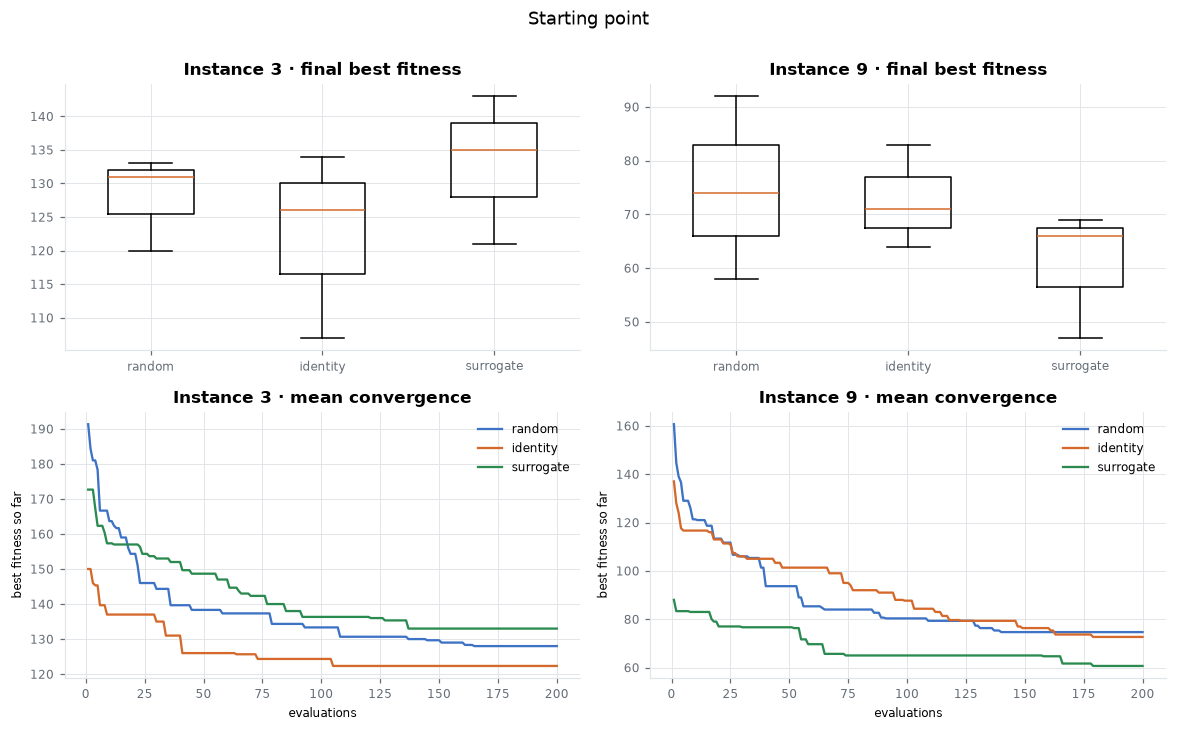

In [15]:
start_study = study("start", {"random": "random", "identity": "identity", "surrogate": "surrogate"}, lambda v: {"start": v})
start_table = display_table(results_frame(start_study))
display(start_table)
plot_study(start_study, "Starting point");

### 2.3 Présélection des voisins par coût de distance

À chaque pas, on génère `candidates` voisins et on n'évalue que le meilleur selon le coût de distance. `1` = recuit simulé classique. Plus la valeur est grande, plus on fait confiance au coût de distance.

Loaded 24 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\simulated_annealing\study_screening.jsonl


instance_id,inst. 3,inst. 9
algorithm,,
c=1,128.3 ± 7.7 (121),63.3 ± 3.7 (59)
c=3,129.3 ± 5.8 (123),64.0 ± 6.4 (55)
c=10,138.0 ± 6.4 (133),60.7 ± 11.7 (50)
c=30,134.0 ± 5.1 (127),64.0 ± 16.1 (46)


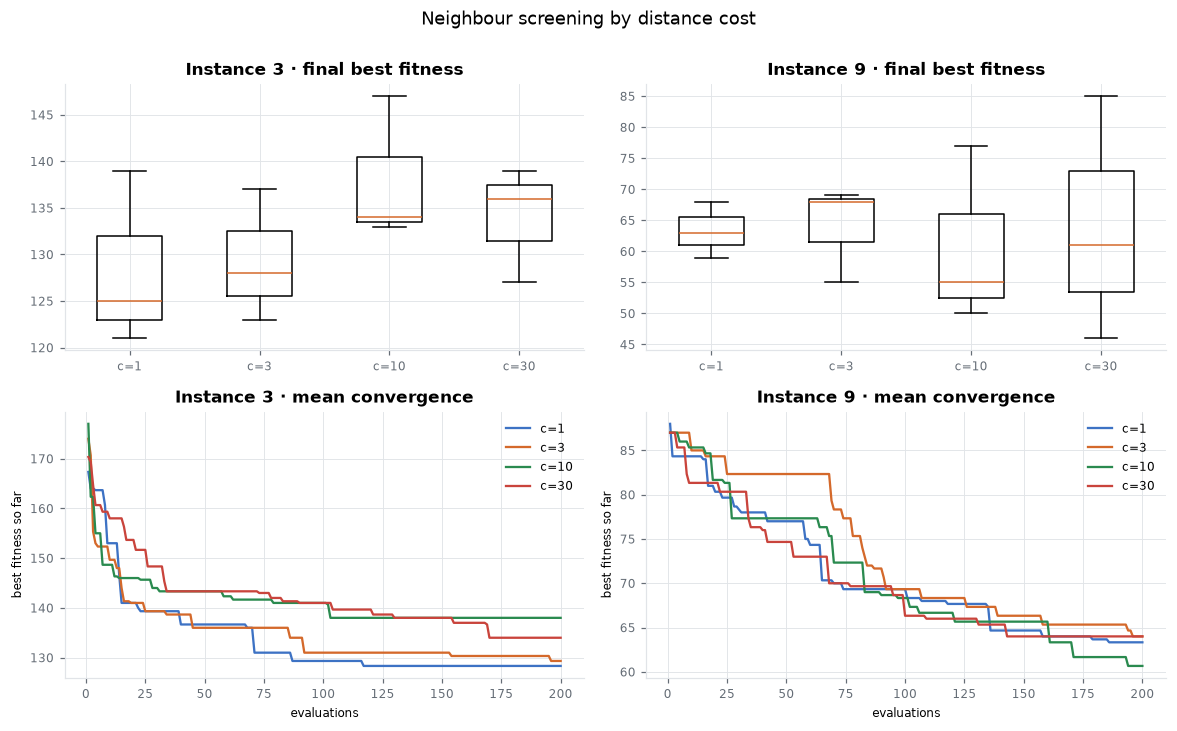

In [16]:
screening_study = study("screening", {"c=1": 1, "c=3": 3, "c=10": 10, "c=30": 30}, lambda v: {"candidates": v})
screening_table = display_table(results_frame(screening_study))
display(screening_table)
plot_study(screening_study, "Neighbour screening by distance cost");

## 3. Comparaison sur toutes les instances

Les références et les trois variantes de fourmis viennent du notebook 04 (relues dans `results/ant_colony/comparison.jsonl`, même budget et mêmes graines). On ajoute :

| Algorithme | Description |
|---|---|
| `sa` | recuit simulé de référence (`BASE_SA`) |
| `sa_screened` | recuit simulé avec présélection de 10 voisins par coût de distance |

In [17]:
# Algorithmes de référence et fourmis : relus depuis le notebook 04 s'ils existent, sinon recalculés ici.
BASELINES = {
    "identity": (identity.run, {}),
    "random_search": (random_search.run, {}),
    "surrogate_filtered": (surrogate_filtered.run, {"candidates": 200}),
    "aco_all": (ant_colony.run, {**ACO_BASE, "ants": 10, "evaluated": 10}),
    "aco_filtered": (ant_colony.run, ACO_BASE),
    "aco_filtered_ls": (ant_colony.run, {**ACO_BASE, "local_search_steps": 200}),
}
if BASELINES_PATH.exists():
    # On ne garde que les exécutions comparables : mêmes instances, mêmes graines, même budget.
    baselines = [r for r in load_results(BASELINES_PATH) if r.instance_id in COMPARISON_INSTANCES and r.seed in SEEDS and r.evaluations == BUDGET]
    print(f"Loaded {len(baselines)} baseline runs from {BASELINES_PATH}")
else:
    baselines = cached_grid("baselines", BASELINES, COMPARISON_INSTANCES, SEEDS, BUDGET)

# Nouveaux algorithmes de ce notebook.
NEW_ALGORITHMS = {
    "sa": (simulated_annealing.run, BASE_SA),
    "sa_screened": (simulated_annealing.run, {**BASE_SA, "candidates": 10}),
}
new_runs = cached_grid("comparison", NEW_ALGORITHMS, COMPARISON_INSTANCES, SEEDS, BUDGET)
comparison = baselines + new_runs
frame = results_frame(comparison)
# Ordre d'affichage : références, fourmis, puis recuit simulé.
ORDER = [name for name in [*BASELINES, *NEW_ALGORITHMS] if name in set(frame["algorithm"])]

Loaded 270 baseline runs from C:\Users\hugo-\Desktop\Projet-GOC\results\ant_colony\comparison.jsonl
Loaded 90 runs from C:\Users\hugo-\Desktop\Projet-GOC\results\simulated_annealing\comparison.jsonl


**Tableau comparatif** : `moyenne ± écart-type (meilleur)` du meilleur coût trouvé sur les graines.

In [18]:
summary_table = display_table(frame).reindex(ORDER)
summary_table

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,57.0 ± 0.0 (57),59.0 ± 0.0 (59),141.0 ± 0.0 (141),62.0 ± 0.0 (62),332.2 ± 1.0 (331),78.2 ± 2.4 (77),107.0 ± 0.0 (107),66.8 ± 1.0 (66),137.0 ± 0.0 (137)
random_search,38.4 ± 2.1 (36),90.2 ± 4.5 (86),139.4 ± 5.2 (132),42.4 ± 0.8 (42),334.0 ± 9.0 (323),39.6 ± 3.7 (35),73.6 ± 7.2 (63),40.0 ± 3.8 (34),98.2 ± 3.5 (93)
surrogate_filtered,34.8 ± 1.7 (33),75.8 ± 2.9 (71),140.0 ± 2.2 (137),38.8 ± 1.5 (36),332.0 ± 4.9 (326),33.8 ± 2.1 (31),64.6 ± 6.3 (57),38.4 ± 2.4 (34),90.2 ± 10.4 (79)
aco_all,28.6 ± 2.9 (25),59.0 ± 0.0 (59),131.0 ± 3.7 (124),36.2 ± 1.0 (35),324.8 ± 2.9 (320),25.6 ± 1.2 (25),39.8 ± 5.9 (34),25.8 ± 3.9 (22),69.8 ± 6.4 (59)
aco_filtered,30.0 ± 0.9 (29),59.0 ± 0.0 (59),128.0 ± 5.2 (122),33.8 ± 2.4 (30),323.0 ± 4.4 (317),25.0 ± 0.0 (25),25.2 ± 2.9 (22),21.6 ± 2.0 (19),54.4 ± 2.8 (51)
aco_filtered_ls,33.4 ± 1.5 (32),59.0 ± 0.0 (59),132.4 ± 2.5 (130),38.6 ± 2.6 (35),328.6 ± 0.5 (328),26.2 ± 1.5 (25),22.6 ± 1.2 (22),19.2 ± 1.9 (17),53.8 ± 2.4 (51)
sa,31.6 ± 0.8 (31),62.8 ± 4.7 (59),131.0 ± 4.9 (125),36.2 ± 0.7 (35),324.2 ± 6.4 (315),30.4 ± 2.2 (28),31.6 ± 4.2 (25),27.0 ± 2.3 (24),56.8 ± 9.0 (43)
sa_screened,31.2 ± 1.2 (30),59.0 ± 0.0 (59),132.2 ± 4.7 (124),34.4 ± 2.5 (31),321.4 ± 3.0 (317),26.2 ± 1.5 (25),29.8 ± 4.5 (25),22.2 ± 2.5 (19),52.8 ± 7.0 (45)


**Gain moyen par rapport à l'identité** (en %, positif = meilleur que l'identité) :

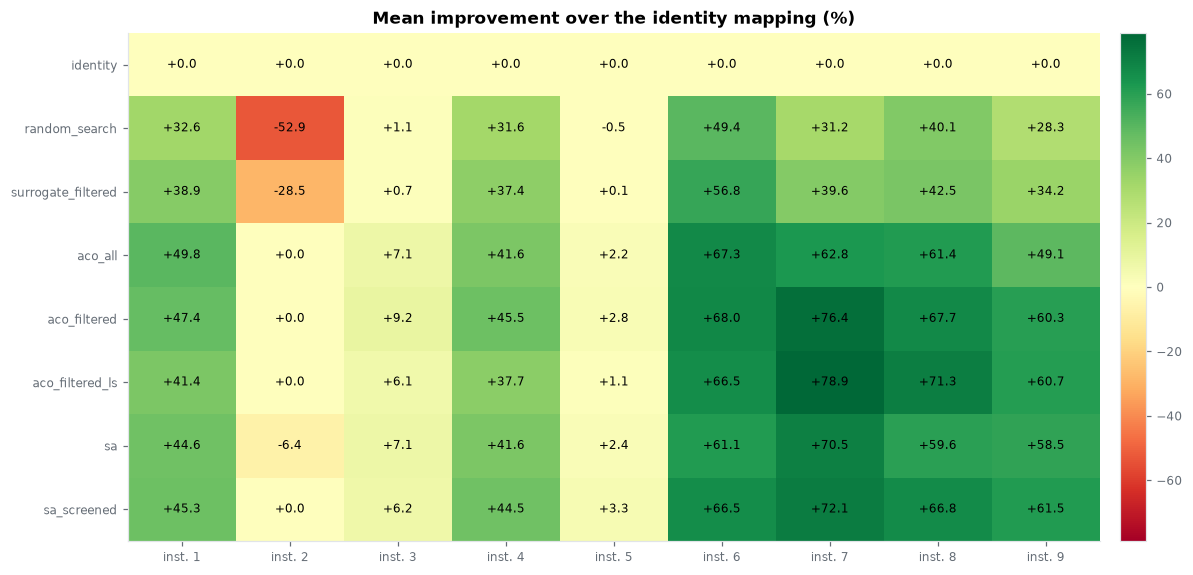

In [19]:
def gain_table(frame, reference="identity"):
    """Gain moyen de chaque algorithme par rapport à la référence, en % : 100 × (référence − algorithme) / référence."""
    means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack()
    return (100 * (means.loc[reference] - means) / means.loc[reference]).round(1)


def plot_gain_heatmap(gains):
    """Carte de chaleur des gains : vert = mieux que l'identité, rouge = moins bien."""
    limit = max(5.0, float(np.nanmax(np.abs(gains.values))))
    fig, ax = plt.subplots(figsize=(1.0 * gains.shape[1] + 3, 0.55 * gains.shape[0] + 1.6))
    image = ax.imshow(gains.values, cmap="RdYlGn", vmin=-limit, vmax=limit, aspect="auto")
    for (i, j), value in np.ndenumerate(gains.values):
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(gains.shape[1]), [f"inst. {c}" for c in gains.columns])
    ax.set_yticks(range(gains.shape[0]), gains.index)
    ax.grid(False)
    ax.set_title("Mean improvement over the identity mapping (%)")
    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
    return fig


gains = gain_table(frame).reindex(ORDER)
plot_gain_heatmap(gains);

**Classement** : rang de chaque algorithme par instance (1 = meilleure moyenne), puis rang moyen.

In [20]:
means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack()
ranks = means.rank(axis=0, method="min").rename(columns=lambda c: f"inst. {c}")
ranks["mean rank"] = ranks.mean(axis=1).round(2)
ranks = ranks.sort_values("mean rank")
ranks

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9,mean rank
algorithm,,,,,,,,,,
aco_filtered,2.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,3.0,1.67
sa_screened,3.0,1.0,4.0,2.0,1.0,3.0,3.0,3.0,1.0,2.33
aco_all,1.0,1.0,2.0,3.0,4.0,2.0,5.0,4.0,5.0,3.00
aco_filtered_ls,5.0,1.0,5.0,5.0,5.0,3.0,1.0,1.0,2.0,3.11
sa,4.0,6.0,2.0,3.0,3.0,5.0,4.0,5.0,4.0,4.00
surrogate_filtered,6.0,7.0,7.0,6.0,6.0,6.0,6.0,6.0,6.0,6.22
identity,8.0,1.0,8.0,8.0,7.0,8.0,8.0,8.0,8.0,7.11
random_search,7.0,8.0,6.0,7.0,8.0,7.0,7.0,7.0,7.0,7.11


**Fourmis contre recuit simulé, instance par instance.** Pour chaque instance, la meilleure variante de chaque famille (en moyenne), en gain par rapport à l'identité.

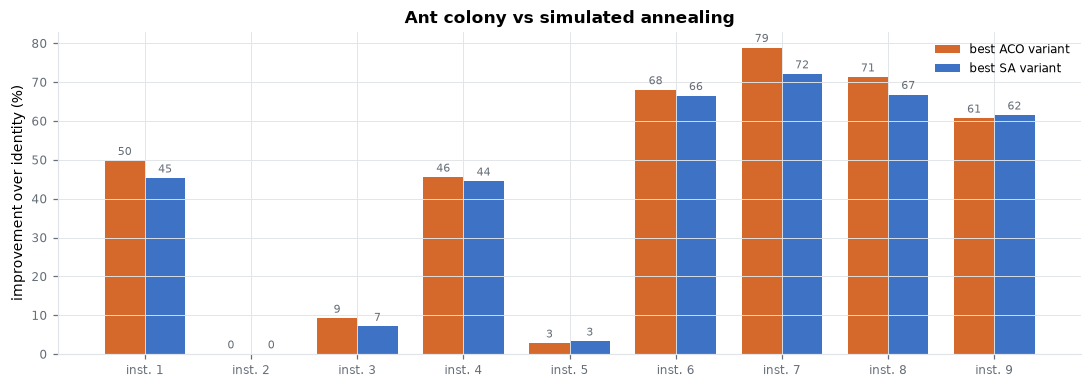

In [21]:
def plot_family_duel(gains):
    """Barres groupées : meilleure variante fourmis et meilleure variante recuit simulé, par instance."""
    families = {
        "best ACO variant": [a for a in gains.index if a.startswith("aco_")],
        "best SA variant": [a for a in gains.index if a.startswith("sa")],
    }
    fig, ax = plt.subplots(figsize=(12, 3.8))
    x = np.arange(gains.shape[1])
    width = 0.38
    for offset, color, (label, members) in zip((-width / 2, width / 2), (PALETTE[1], PALETTE[0]), families.items()):
        # Meilleur gain parmi les variantes de la famille, pour chaque instance.
        values = gains.loc[members].max(axis=0)
        bars = ax.bar(x + offset, values, width, color=color, label=label)
        ax.bar_label(bars, fmt="%.0f", fontsize=7, color=MUTED, padding=2)
    ax.set_xticks(x, [f"inst. {c}" for c in gains.columns])
    ax.set_ylabel("improvement over identity (%)")
    ax.set_title("Ant colony vs simulated annealing")
    ax.legend()
    return fig


plot_family_duel(gains);

**Significativité.** Test de Mann-Whitney unilatéral : *p-value* < 0,05 = l'algorithme en ligne du titre est très probablement meilleur que celui de la colonne sur cette instance. Avec 5 graines, une valeur élevée ne prouve pas l'égalité.

In [22]:
def significance(frame, algorithm, others):
    """p-values du test de Mann-Whitney « algorithm est meilleur que other », par instance (lignes) et adversaire (colonnes)."""
    rows = {}
    for instance_id in sorted(frame["instance_id"].unique()):
        subset = frame[frame["instance_id"] == instance_id]
        target = subset.loc[subset["algorithm"] == algorithm, "best_cost"]
        rows[f"inst. {instance_id}"] = {
            other: stats.mannwhitneyu(target, subset.loc[subset["algorithm"] == other, "best_cost"], alternative="less").pvalue
            for other in others if other in set(subset["algorithm"])
        }
    return pd.DataFrame(rows).T.round(4)


sa_p_values = significance(frame, "sa", ["random_search", "surrogate_filtered", "aco_filtered"])
print("sa better than ...")
display(sa_p_values)
screened_p_values = significance(frame, "sa_screened", ["random_search", "surrogate_filtered", "aco_filtered"])
print("sa_screened better than ...")
display(screened_p_values)

sa better than ...


,random_search,surrogate_filtered,aco_filtered
inst. 1,0.0056,0.0072,0.9873
inst. 2,0.0055,0.0056,0.9495
inst. 3,0.0375,0.0181,0.8452
inst. 4,0.0046,0.0274,0.9674
inst. 5,0.1111,0.0706,0.7004
inst. 6,0.0057,0.0352,0.9982
inst. 7,0.0040,0.0060,0.9863
inst. 8,0.0040,0.0040,0.9922
inst. 9,0.0040,0.0040,0.7009


sa_screened better than ...


,random_search,surrogate_filtered,aco_filtered
inst. 1,0.0060,0.0077,0.9337
inst. 2,0.0036,0.0037,1.0000
inst. 3,0.0375,0.0078,0.8964
inst. 4,0.0047,0.0175,0.7371
inst. 5,0.0233,0.0040,0.2616
inst. 6,0.0053,0.0055,0.9505
inst. 7,0.0058,0.0057,0.9557
inst. 8,0.0060,0.0060,0.6653
inst. 9,0.0040,0.0040,0.1981


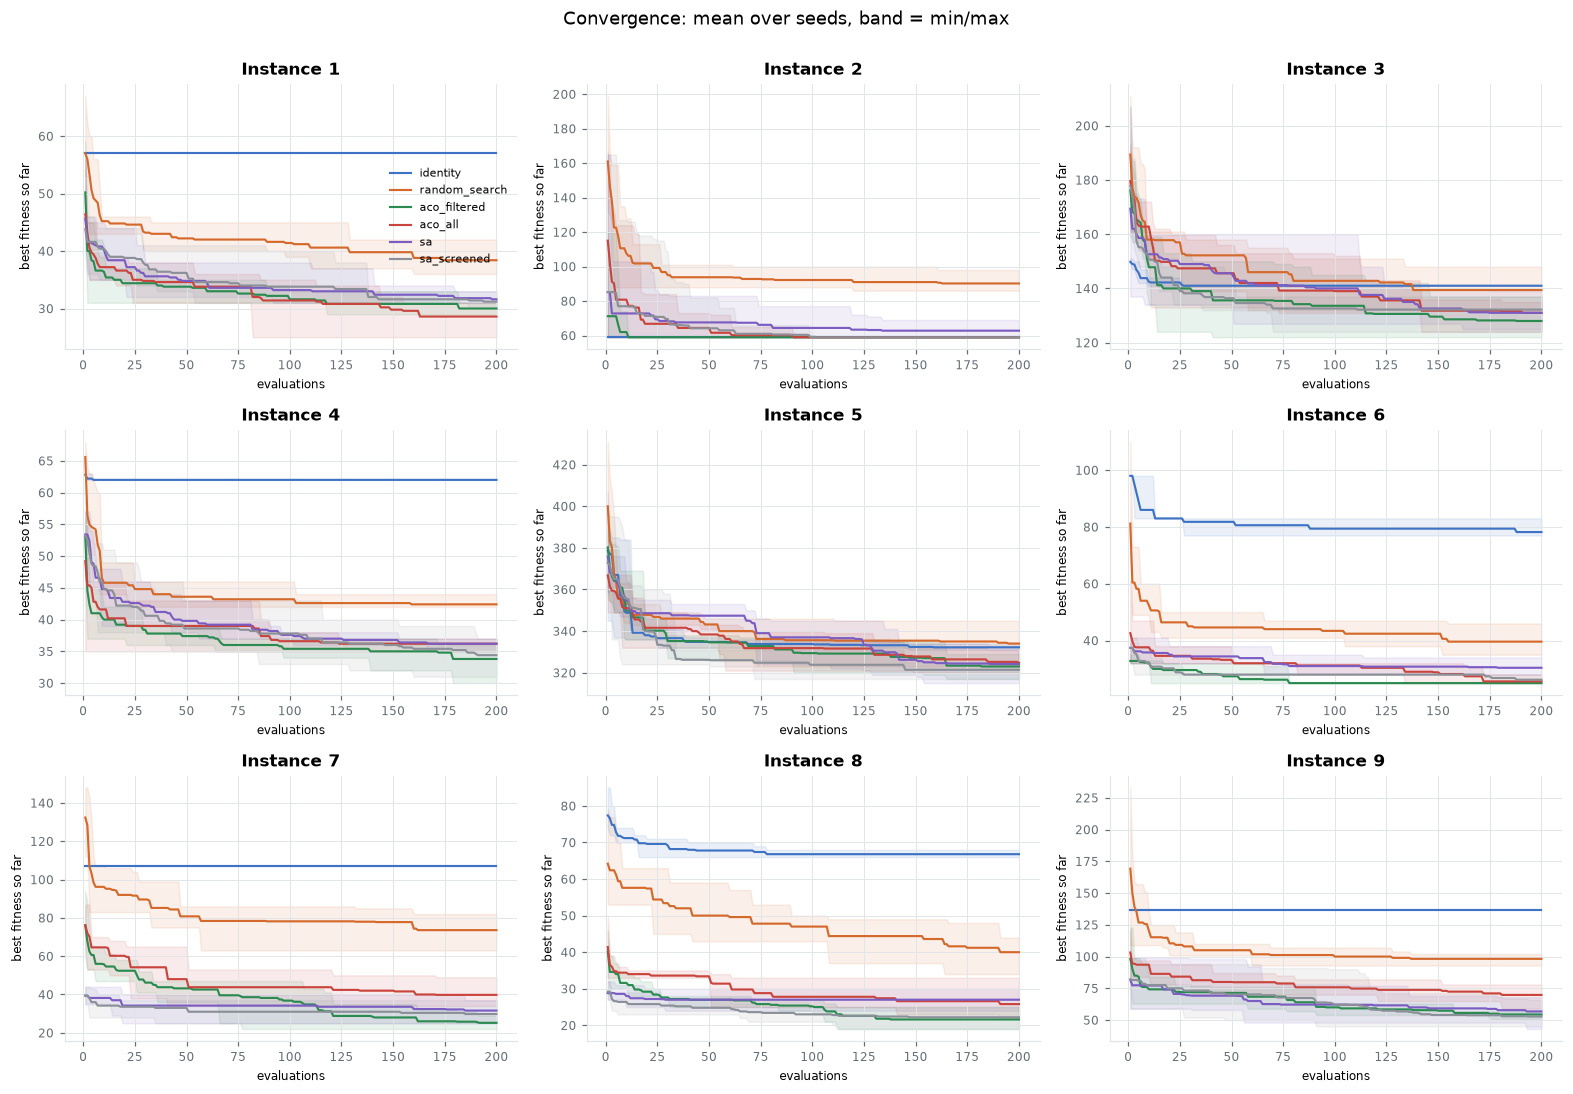

In [23]:
def plot_convergence(results, order):
    """Courbes de convergence des algorithmes choisis sur chaque instance (moyenne sur les graines, bande min/max)."""
    history = history_frame(results)
    instance_ids = sorted(history["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=4.8, height=3.3)
    for ax, instance_id in zip(axes, instance_ids):
        subset = history[history["instance_id"] == instance_id]
        for color, algorithm in zip(PALETTE, order):
            curves = subset[subset["algorithm"] == algorithm].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=color, label=algorithm, linewidth=1.4)
            ax.fill_between(curves.index, curves.min(axis=1), curves.max(axis=1), color=color, alpha=0.1)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
    axes[0].legend(fontsize=7)
    fig.suptitle("Convergence: mean over seeds, band = min/max", y=1.0)
    fig.tight_layout()
    return fig


# Six algorithmes représentatifs, pour garder les courbes lisibles.
CONVERGENCE_ORDER = [a for a in ["identity", "random_search", "aco_filtered", "aco_all", "sa", "sa_screened"] if a in ORDER]
plot_convergence([r for r in comparison if r.algorithm in CONVERGENCE_ORDER], CONVERGENCE_ORDER);

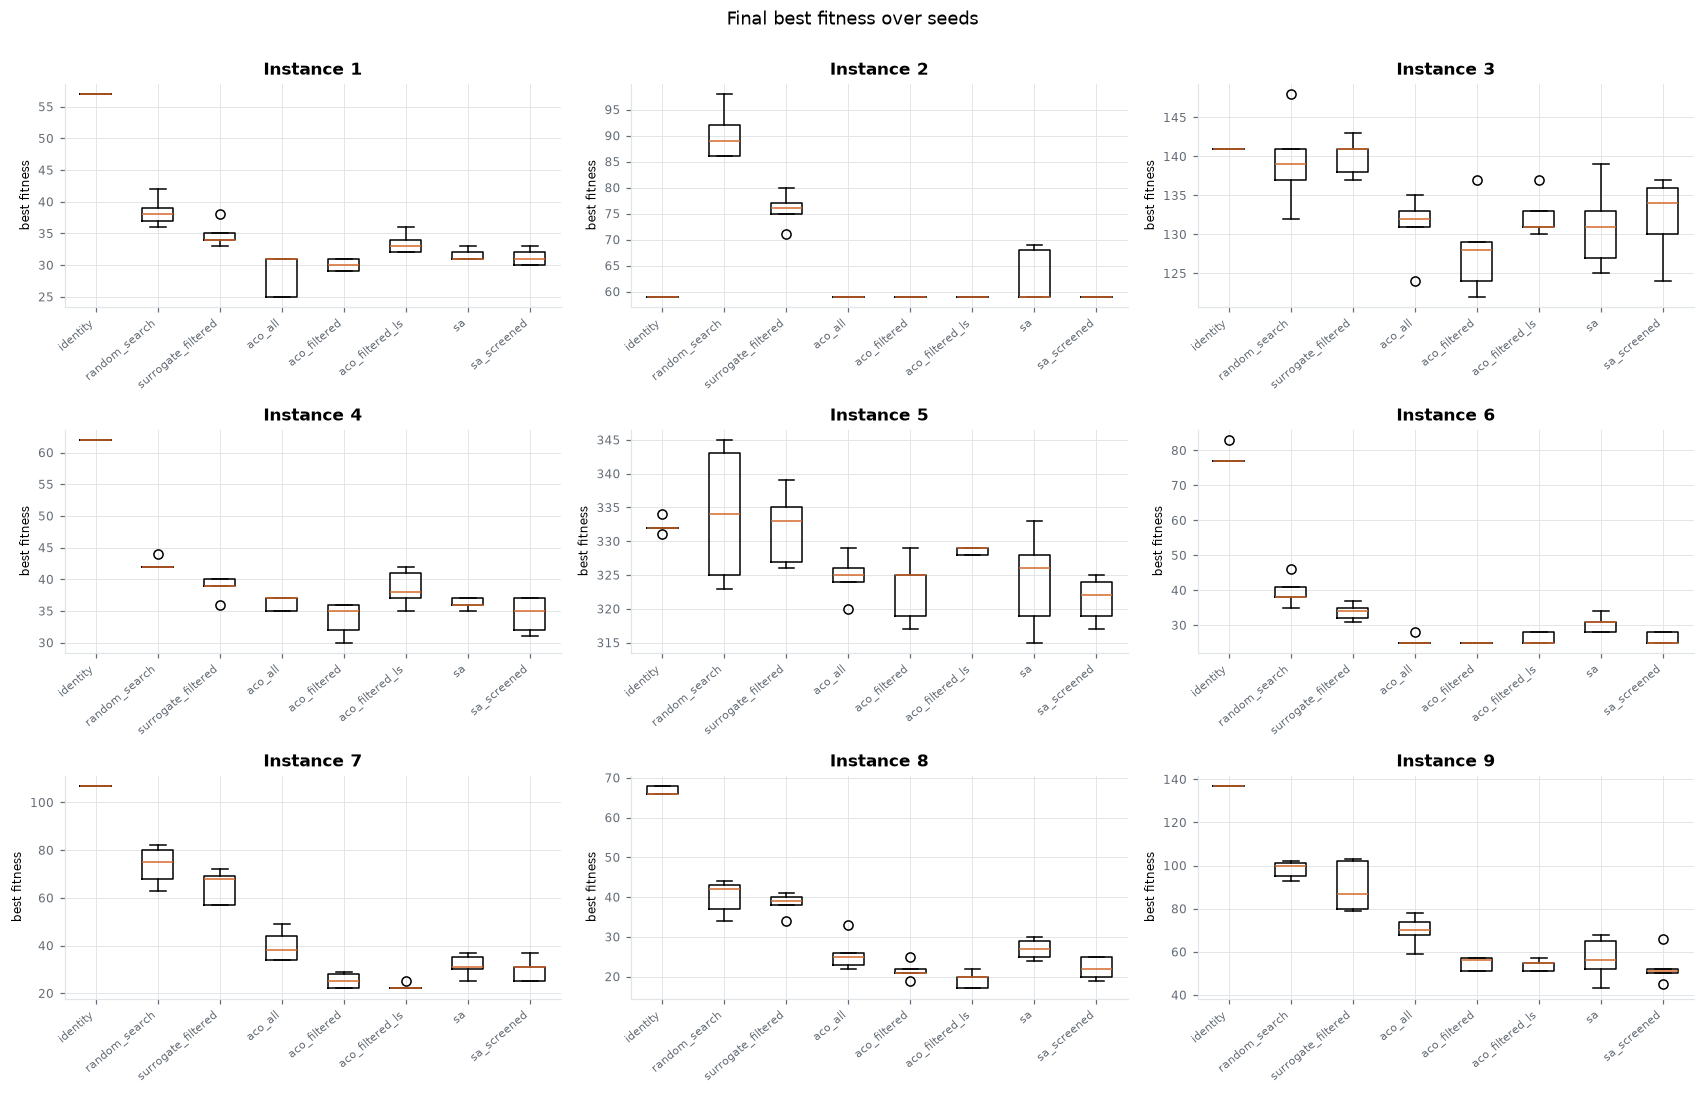

In [24]:
def plot_result_boxplots(frame, order):
    """Boîtes à moustaches du meilleur coût final, par instance et par algorithme."""
    instance_ids = sorted(frame["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=5.2, height=3.3)
    for ax, instance_id in zip(axes, instance_ids):
        subset = frame[frame["instance_id"] == instance_id]
        ax.boxplot([subset.loc[subset["algorithm"] == a, "best_cost"] for a in order], widths=0.5, medianprops={"color": LOGICAL})
        ax.set_xticks(range(1, len(order) + 1), order, rotation=40, ha="right", fontsize=7)
        ax.set_title(f"Instance {instance_id}")
        ax.set_ylabel("best fitness", fontsize=8)
    fig.suptitle("Final best fitness over seeds", y=1.0)
    fig.tight_layout()
    return fig


plot_result_boxplots(frame, ORDER);

**Temps moyen d'une exécution** (secondes, budget complet).

In [25]:
run_times = frame.groupby(["algorithm", "instance_id"])["seconds"].mean().unstack().reindex(ORDER).round(1).rename(columns=lambda c: f"inst. {c}")
run_times

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,32.1,109.8,58.8,30.5,78.7,42.4,44.7,51.0,47.5
random_search,34.1,158.0,72.5,37.5,92.6,47.9,52.3,56.2,55.2
surrogate_filtered,31.1,139.1,59.3,29.7,80.9,40.9,43.1,48.6,51.7
aco_all,32.5,137.8,63.7,33.2,86.5,45.1,41.3,43.5,42.7
aco_filtered,32.1,133.8,59.3,37.8,95.2,45.7,40.8,48.9,47.0
aco_filtered_ls,45.0,131.2,73.4,33.3,57.3,22.9,19.1,24.3,22.8
sa,9.6,83.7,28.8,8.9,44.0,15.3,13.4,18.7,18.7
sa_screened,9.5,77.4,28.5,8.9,37.6,12.0,9.0,15.5,14.2


## 4. Meilleures solutions, tous algorithmes confondus

Pour chaque instance : le meilleur placement trouvé par **n'importe quel** algorithme de la comparaison, réévalué `REEVALUATIONS` fois. Le fichier `GROUP_Challenge_N.txt` n'est écrit que si son coût est **meilleur** que celui déjà enregistré dans `solutions/`.

In [26]:
rows = []
for instance_id in COMPARISON_INSTANCES:
    # Meilleure exécution sur cette instance, tous algorithmes et graines confondus.
    best = min((r for r in comparison if r.instance_id == instance_id), key=lambda r: r.best_cost)
    checks = Problem(load_instance(instance_id)).fitness_samples(best.best_mapping, REEVALUATIONS)
    cost = min(best.best_cost, min(checks))
    path, written, previous = write_solution_if_better(best.best_mapping, cost, instance_id, group=GROUP, directory=SOLUTIONS_DIR)
    rows.append({
        "instance": instance_id,
        "algorithm": best.algorithm,
        "seed": best.seed,
        "cost during search": best.best_cost,
        "re-evaluation min": min(checks),
        "re-evaluation mean": round(float(np.mean(checks)), 2),
        "re-evaluation std": round(float(np.std(checks)), 2),
        "file": path.name,
        "file status": "written" if written else f"kept (existing cost {previous:g})",
        "mapping": " ".join(map(str, best.best_mapping)),
    })
best_solutions = pd.DataFrame(rows).set_index("instance")
best_solutions

,algorithm,seed,cost during search,re-evaluation min,re-evaluation mean,re-evaluation std,file,file status,mapping
instance,,,,,,,,,
1,aco_all,2,25,25,27.8,2.86,Groupe0_Challenge_1.txt,kept (existing cost 25),0 14 13 2 12 3 11 15 4 10 5 1
2,identity,0,59,59,59.0,0.00,Groupe0_Challenge_2.txt,kept (existing cost 59),0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
3,aco_filtered,0,122,124,139.9,7.41,Groupe0_Challenge_3.txt,kept (existing cost 122),6 9 10 7 12 3 4 11 8 5
4,aco_filtered,3,30,30,30.9,1.37,Groupe0_Challenge_4.txt,kept (existing cost 30),7 8 12 6 1 16 14 4 13 2 10 18 11 3 0 19 9 5 17
5,sa,4,315,314,317.5,2.38,Groupe0_Challenge_5.txt,written,3 8 10 4 17 14 6 5 7 12 0 9
6,aco_all,0,25,25,25.0,0.00,Groupe0_Challenge_6.txt,kept (existing cost 25),1 13 8 3 11 10 5 16 9 14 6 2 18 7
7,aco_filtered,0,22,22,22.0,0.00,Groupe0_Challenge_7.txt,kept (existing cost 22),9 8 5 3 2 1 4 7 12 10 13 14 16 19 22 24 25 23 ...
8,aco_filtered_ls,0,17,17,17.6,1.50,Groupe0_Challenge_8.txt,kept (existing cost 17),14 13 23 24 10 12 3 5 19 22 25 8 21 15 18 2 16...
9,sa,0,43,43,44.8,1.47,Groupe0_Challenge_9.txt,kept (existing cost 43),20 9 10 22 16 21 6 5 0 1 8 4 2 3 11 12 15 14 1...


## Conclusions

_Exécution du 15/11/2026 : budget de 200 évaluations, 5 graines, 9 instances ; références et fourmis relues du notebook 04. Les chiffres bougent un peu d'une exécution à l'autre, les tendances non. La comparaison de toutes les métaheuristiques est tenue à jour dans le notebook `99_comparison`._

### Le recuit simulé face aux autres méthodes

| Rang moyen | Algorithme |
|---|---|
| 1,67 | `aco_filtered` (fourmis) |
| 2,33 | `sa_screened` (recuit simulé avec présélection de 10 voisins) |
| 3,00 | `aco_all` (fourmis, toutes évaluées) |
| 4,00 | `sa` (recuit simulé classique) |
| 6,2 et plus | références |

- **`sa_screened` bat les références partout** : significativement meilleur que `random_search` et `surrogate_filtered` sur les 9 instances, et 1er sur les instances 5 et 9.
- **`sa` bat les références sur 8 instances sur 9** (pas sur l'instance 5, p ≈ 0,07 à 0,11).
- **Aucune variante du recuit ne bat `aco_filtered` en moyenne** (p ≥ 0,20 partout) : à 200 évaluations, les fourmis restent la méthode la plus régulière.

### De meilleures solutions ponctuelles

Le recuit simulé varie beaucoup d'une graine à l'autre, mais ses meilleures exécutions dépassent tout ce que les fourmis ont trouvé :
- **instance 9** : 43 (réévalué : ≈ 45 en moyenne), contre 51 au mieux pour les fourmis ;
- **instance 5** : 315 pendant la recherche, 314 lors d'une réévaluation (≈ 317,5 en moyenne : solution stable), contre 317 au mieux pour les fourmis.

Ces solutions sont dans `solutions/` ; les autres fichiers ont été conservés car déjà meilleurs.

### Ce que disent les études de paramètres (instances 3 et 9, 3 graines)

- **Température** : les voisins proposés sont presque toujours beaucoup plus mauvais que le placement courant (dans l'exécution détaillée, 183 dégradations refusées pour 2 acceptées). Une température basse (0,5 %, presque une descente pure) fait donc aussi bien que 5 %, tandis qu'une température haute (15 %) gaspille le budget (instance 9 : 79 au lieu de 52).
- **Point de départ** : c'est le réglage le plus important, et il dépend de l'instance. Sur l'instance 9, le départ optimisé pour le coût de distance est le meilleur (60,7 contre ≈ 73 à 75). Sur l'instance 3 (QFT), c'est un piège : le départ identité fait mieux (122,3 contre 133,0), et une de ces exécutions a même atteint **107**, la meilleure valeur jamais vue sur cette instance.
- **Présélection des voisins** : elle aide un peu sur l'instance 9 (coût de distance fiable) mais dégrade l'instance 3 (c = 10 : 138 au lieu de 128), comme prévu par le notebook 02.

### Limites

- **Forte variance entre graines** (instance 9 : de 43 à plus de 65 selon la graine) : avec 5 graines, les comparaisons restent fragiles.
- **Temps d'exécution non comparables** avec le notebook 04 : ses exécutions ont tourné sur une machine plus chargée.
- Le coût de la meilleure solution de l'instance 3 reste optimiste (122 pendant la recherche, ≈ 140 en moyenne à la réévaluation).

### Pistes

1. **Départ identité sur les instances 3 et 5**, où le coût de distance guide mal : la piste la plus prometteuse vu le 107 obtenu sur l'instance 3.
2. **Redémarrages multiples** : plusieurs recuits courts plutôt qu'un long, pour exploiter la forte variance (on garde le meilleur).
3. **Température adaptée aux écarts réels** : calibrer `t_start` sur la taille typique des dégradations observées plutôt que sur le coût de départ.
4. **Choisir les solutions rendues par réévaluation** (meilleure moyenne sur plusieurs évaluations), pour ne pas rendre un coût obtenu par chance.